# Real-time-informed fibroblast pseudotime — mouse & human

Species-parametrized port of `realtime_informed_pseudotime_human.ipynb`, updated for the
**2026_08_28 deliverable objects** and the **v2 annotation vocabulary**.

Pipeline (unchanged): HVG → scVI → moscot `TemporalProblem` → CellRank `RealTimeKernel`
→ symmetrized transition matrix → DPT eigen-decomposition → DPT pseudotime.

**Set `SPECIES` in the next cell and Restart & Run All.** Outputs are per-species and
per-variant, so runs never collide.

---

## Read this before running: the two species are not symmetric

| | mouse | human |
|---|---|---|
| fib/dec cells | 43,197 | 47,533 |
| fine stromal subtypes | **9** | **0 — all coarse-filled** |
| `efib_proliferative` root anchor | 780 cells | **absent** |
| timepoints | 6 → 5 transitions | 2 → 1 transition |

Consequences:

1. **Root selection differs by necessity.** Mouse anchors on `efib_proliferative`.
   Human has no fine stromal labels, so it falls back to earliest-timepoint cells
   (`secretory`). The notebook reports which path it took — do not read a human root as
   biologically anchored the way the mouse one is.
2. **The real-time signal is much weaker for human.** Two timepoints give moscot a single
   transition, so the "real-time-informed" part is doing far less work than on mouse.
3. Human pseudotime here is *mostly* diffusion geometry with one temporal constraint.
   Interpret accordingly.

## Species switch

In [1]:
SPECIES = "mouse"          # "mouse" | "human"
VARIANT = "v1_all_cells"   # names the output folder

## Library imports

In [2]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from scipy.sparse import csr_matrix, issparse
import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import cellrank as cr
from anndata import AnnData
from scanpy.tools._dpt import DPT

import jax

from gpu_utils import *

gpu_utils: rapids-singlecell loaded. GPU acceleration enabled


## Configuration

Per-species blocks. Labels are **v2 vocabulary** — the old codes (`eFib1`, `dec1`,
`eFibP`) no longer exist in these objects.

In [3]:
DELIVERABLES = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/deliverables")
DATE_TAG = "2026_08_28"

SPECIES_CONFIG = {
    # ------------------------------------------------------------------ MOUSE
    "mouse": {
        "species_tag": "XMens",
        "moscot_gene_set": "mouse",          # proliferation/apoptosis marker set

        # v2 vocabulary. cell_subtype carries 9 fine stromal labels here.
        "cluster_key": "cell_subtype",
        "root_candidate_label": "efib_proliferative",       # was eFibP
        "fibroblast_labels_to_remove": [
            "efib_outer", "efib_middle", "efib_middle_induced", "efib_subluminal",
        ],                                                   # intentionally keeps efib_proliferative
        "apoptotic_labels": ["decidual_apoptotic"],          # was decAp

        # Six timepoints -> numeric day. dpi = days post-induction; early/late split
        # within day 1 is represented as 1.0 / 1.5 (see the note below).
        "timepoint_to_day": {
            "uninduced":      0.0,
            "1_dpi_early":    1.0,
            "1_dpi_late":     1.5,
            "2_dpi":          2.0,
            "3_dpi":          3.0,
            "4_dpi_bleeding": 4.0,
        },
    },
    # ------------------------------------------------------------------ HUMAN
    "human": {
        "species_tag": "Human",
        "moscot_gene_set": "human",

        # NOTE: human cell_subtype is 100% coarse-filled (no fine stromal labels),
        # so root_candidate_label will NOT be found and the notebook falls back to
        # earliest-timepoint cells. That fallback is expected here, not a failure.
        "cluster_key": "cell_subtype",
        "root_candidate_label": "efib_proliferative",
        "fibroblast_labels_to_remove": [],
        "apoptotic_labels": [],

        # Menstrual cycle phases, not dpi. Only TWO timepoints -> one transition.
        "timepoint_to_day": {
            "secretory": 0.0,
            "menstrual": 1.0,
        },
    },
}

CONFIG = {
    "variant_name": VARIANT,

    # Filters (cumulative)
    "remove_uninduced":   False,   # mouse only; no 'uninduced' timepoint in human
    "remove_fibroblasts": False,
    "remove_apoptotic":   False,

    # scVI latent source. VERIFIED 2026-08-28 against the objects on disk:
    #   "04b"     -> adopt data/interim/latent_{species}_stromal.h5ad, the per-lineage
    #                scVI fit from 04b_reintegrate. mouse: 43,197 cells in the SAME
    #                order as the deliverable. human: 48,004 (superset, +471
    #                perivascular throwbacks) -> subset by obs_names.
    #                This is what the headless runs used.
    #   "retrain" -> fit scVI fresh on the filtered subset (200 epochs, GPU).
    #   "reuse"   -> use the X_scVI already on the deliverable. NOT RECOMMENDED: it
    #                is a row-subset of the WHOLE-TISSUE fit from 04e_reembed, and
    #                subsetting a latent is not the same as fitting on the subset.
    #                moscot uses this latent as its cost geometry, so a space that
    #                does not resolve stromal substructure gives couplings that
    #                cannot either.
    "scvi_source": "04b",
    "scvi_n_latent": 30,
    "scvi_n_layers": 2,
    "scvi_max_epochs": 200,
    "n_hvg": 3000,
    "counts_layer": "counts",        # v2 objects keep ONLY 'counts' (was 'raw')
    "batch_key": "sample",

    # moscot solver
    "moscot_epsilon": 1e-3,
    "moscot_tau_a":   0.95,
    "moscot_tau_b":   0.95,

    # RealTimeKernel
    "rtk_conn_weight": 0.2,
    "rtk_self_transitions": "all",
    "rtk_threshold": "auto",

    "n_diffmap_comps": 15,
    "seed": 0,

    # Root direction within the candidate pool, along DC2/DC3:
    #   "far"  -> cell FARTHEST from the centroid of non-candidates (argmax)
    #   "near" -> cell CLOSEST to it (argmin)
    #
    # MOUSE NEEDS "near". With "far" the root landed on a 3_dpi cell at the late
    # end of the diffusion axis and pseudotime ran BACKWARDS: rho(pt, day) =
    # -0.4933 and rho(pt, subtype_rank) = -0.7693, with decidual_mature scoring
    # the LOWEST pseudotime. The |rho| = 0.77 says the trajectory is strong and
    # coherent; the sign says it points the wrong way. Flip the root, never negate
    # dpt_pseudotime — downstream code assumes [0, 1].
    "root_direction": "near",

    # Spatial. v2 objects keep raw dbscan coords in obs AND obsm['X_spatial'].
    "spatial_sample_col": "sample",
    "spatial_x_col": "x_um_dbscan",
    "spatial_y_col": "y_um_dbscan",
}

CONFIG.update(SPECIES_CONFIG[SPECIES])

for k, v in CONFIG.items():
    print(f"  {k:30s} = {v}")

  variant_name                   = v1_all_cells
  remove_uninduced               = False
  remove_fibroblasts             = False
  remove_apoptotic               = False
  scvi_source                    = 04b
  scvi_n_latent                  = 30
  scvi_n_layers                  = 2
  scvi_max_epochs                = 200
  n_hvg                          = 3000
  counts_layer                   = counts
  batch_key                      = sample
  moscot_epsilon                 = 0.001
  moscot_tau_a                   = 0.95
  moscot_tau_b                   = 0.95
  rtk_conn_weight                = 0.2
  rtk_self_transitions           = all
  rtk_threshold                  = auto
  n_diffmap_comps                = 15
  seed                           = 0
  root_direction                 = near
  spatial_sample_col             = sample
  spatial_x_col                  = x_um_dbscan
  spatial_y_col                  = y_um_dbscan
  species_tag                    = XMens
  moscot_gene_set    

### A note on the mouse day mapping

`1_dpi_early` and `1_dpi_late` are both day 1. Encoding them as **1.0 / 1.5** keeps their
order and makes the early→late gap half of a full day-to-day step.

moscot couples *consecutive* timepoints, so this spacing sets how much mass movement the
solver expects between those two. If the real interval is known (hours post-induction),
put it here — it is the one parameter in this notebook with a directly biological value.
Sensitivity is worth checking: rerun with `1_dpi_late: 1.25` and again with `1.75` and
compare the day↔pseudotime Spearman ρ reported in the diagnostics.

## Paths & settings

In [4]:
ADATA_PATH = DELIVERABLES / f"{DATE_TAG}_Cevrim_{CONFIG['species_tag']}_Only_Fib_Dec_Cells.h5ad"

OUT_ROOT    = Path(f"./pseudotime_{SPECIES}")
FIG_DIR     = OUT_ROOT / "figures" / VARIANT
RESULTS_DIR = OUT_ROOT / "results" / VARIANT
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_FORMAT = "pdf"
SAVE_FIGURES = True

sc.settings.verbosity = 2
cr.settings.verbosity = 2
np.random.seed(CONFIG["seed"])

assert ADATA_PATH.is_file(), f"adata not found at {ADATA_PATH}"
print(f"Species:  {SPECIES}")
print(f"Variant:  {VARIANT}")
print(f"Input:    {ADATA_PATH}")
print(f"Figures:  {FIG_DIR}")
print(f"Results:  {RESULTS_DIR}")
print(f"JAX backend: {jax.default_backend()}  devices: {jax.devices()}")
assert jax.default_backend() == "gpu", (
    "JAX not on GPU — moscot will be unusably slow. Restart the kernel on a GPU node "
    "with jax[cuda12] installed."
)

Species:  mouse
Variant:  v1_all_cells
Input:    /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/deliverables/2026_08_28_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
Figures:  pseudotime_mouse/figures/v1_all_cells
Results:  pseudotime_mouse/results/v1_all_cells


2026-08-28 23:02:52 | [INFO] Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


JAX backend: gpu  devices: [CudaDevice(id=0)]


## Helper functions

In [5]:
def get_symmetric_transition_matrix(transition_matrix):
    """Symmetrize a transition matrix and re-normalize rows."""
    sym_mat = (transition_matrix + transition_matrix.T) / 2
    row_sums = sym_mat.sum(axis=1).A1
    sym_mat.data = sym_mat.data / row_sums[sym_mat.nonzero()[0]]
    return sym_mat


def savefig(name):
    """Save the current figure into the variant figure dir."""
    if SAVE_FIGURES:
        p = FIG_DIR / f"{name}.{FIGURE_FORMAT}"
        plt.savefig(p, bbox_inches="tight", dpi=300)
        print(f"  saved {p}")

## Data loading

In [6]:
adata = sc.read_h5ad(ADATA_PATH)
print(adata)

AnnData object with n_obs × n_vars = 43197 × 33698
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'x_um_dbscan', 'y_um_dbscan', 'cell_type', 'cell_subtype', 'auc_MMy', 'auc_MD', 'auc_VSZ', 'auc_FMI', 'auc_C', 'auc_PDZ', 'auc_TDZ', 'auc_SDZ', 'auc_udStr', 'auc_Glan', 'auc_AMMy'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'annotation_schema_version', 'aucell', 'display_names', 'hvg', 'log1p', 'neighbors_scVI_100', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_spatial', 'X_umap_scVI'
    layers: 'counts'


In [7]:
print("cell_type:")
print(adata.obs["cell_type"].value_counts().to_string())

print(f"\n{CONFIG['cluster_key']}:")
print(adata.obs[CONFIG["cluster_key"]].value_counts().to_string())

print("\ntimepoint:")
print(adata.obs["timepoint"].value_counts().to_string())

print("\nlayers:", list(adata.layers))
print("obsm  :", list(adata.obsm))

# structural expectations for the v2 deliverables
assert CONFIG["counts_layer"] in adata.layers, (
    f"expected layer {CONFIG['counts_layer']!r}, found {list(adata.layers)}"
)
expected_n = {"mouse": 43197, "human": 47533}[SPECIES]
assert adata.n_obs == expected_n, f"expected {expected_n:,} fib/dec cells, got {adata.n_obs:,}"
print(f"\nOK: {adata.n_obs:,} cells, counts layer present")

cell_type:
cell_type
decidual_cell             22919
endometrial_fibroblast    20278

cell_subtype:
cell_subtype
decidual_proliferative    14434
efib_middle_induced        8775
efib_middle                4764
efib_subluminal            3886
decidual_mature            3856
decidual_boundary          3722
efib_outer                 2073
decidual_apoptotic          907
efib_proliferative          780

timepoint:
timepoint
1_dpi_late        10787
3_dpi             10673
uninduced          9334
4_dpi_bleeding     6141
2_dpi              3574
1_dpi_early        2688

layers: ['counts']
obsm  : ['X_scVI', 'X_spatial', 'X_umap_scVI']

OK: 43,197 cells, counts layer present


### Is the root anchor actually present?

Decided here rather than silently at root-selection time.

In [8]:
labels_present = set(adata.obs[CONFIG["cluster_key"]].astype(str).unique())
anchor = CONFIG["root_candidate_label"]

ANCHOR_AVAILABLE = anchor in labels_present
n_anchor = int((adata.obs[CONFIG["cluster_key"]].astype(str) == anchor).sum())

print(f"root anchor {anchor!r} present: {ANCHOR_AVAILABLE}  (n={n_anchor:,})")
if not ANCHOR_AVAILABLE:
    print(
        "\n  -> Falling back to earliest-timepoint cells for the root.\n"
        "     Expected for human: cell_subtype is fully coarse-filled, so no fine\n"
        "     stromal label exists to anchor on. The resulting pseudotime is NOT\n"
        "     anchored the same way the mouse one is."
    )

root anchor 'efib_proliferative' present: True  (n=780)


## Apply variant filters

In [9]:
n_before = adata.n_obs
filter_log = []

if CONFIG["remove_uninduced"]:
    m = (adata.obs["timepoint"] != "uninduced").values
    filter_log.append(f"remove_uninduced: {adata.n_obs} -> {m.sum()}  (-{(~m).sum()})")
    adata = adata[m].copy()

if CONFIG["remove_fibroblasts"] and CONFIG["fibroblast_labels_to_remove"]:
    labels = CONFIG["fibroblast_labels_to_remove"]
    m = (~adata.obs[CONFIG["cluster_key"]].isin(labels)).values
    filter_log.append(f"remove_fibroblasts {labels}: {adata.n_obs} -> {m.sum()}  (-{(~m).sum()})")
    adata = adata[m].copy()

if CONFIG["remove_apoptotic"] and CONFIG["apoptotic_labels"]:
    labels = CONFIG["apoptotic_labels"]
    m = (~adata.obs[CONFIG["cluster_key"]].isin(labels)).values
    filter_log.append(f"remove_apoptotic {labels}: {adata.n_obs} -> {m.sum()}  (-{(~m).sum()})")
    adata = adata[m].copy()

for col in ["timepoint", CONFIG["cluster_key"]]:
    if col in adata.obs.columns and hasattr(adata.obs[col], "cat"):
        adata.obs[col] = adata.obs[col].cat.remove_unused_categories()

print(f"Total: {n_before} -> {adata.n_obs}  (-{n_before - adata.n_obs})")
for line in filter_log:
    print("  " + line)
print("\nRemaining timepoints:", list(adata.obs["timepoint"].astype("category").cat.categories))
print("Remaining subtypes  :", list(adata.obs[CONFIG["cluster_key"]].astype("category").cat.categories))

Total: 43197 -> 43197  (-0)

Remaining timepoints: ['1_dpi_early', '1_dpi_late', '2_dpi', '3_dpi', '4_dpi_bleeding', 'uninduced']
Remaining subtypes  : ['decidual_apoptotic', 'decidual_boundary', 'decidual_mature', 'decidual_proliferative', 'efib_middle', 'efib_middle_induced', 'efib_outer', 'efib_proliferative', 'efib_subluminal']


## Timepoint → day mapping

In [10]:
tp_cat = adata.obs["timepoint"].astype("category")
present_tps = set(tp_cat.cat.categories)
mapping = {tp: d for tp, d in CONFIG["timepoint_to_day"].items() if tp in present_tps}

unmapped = sorted(present_tps - set(CONFIG["timepoint_to_day"]))
assert not unmapped, f"timepoints with no day mapping: {unmapped}"

adata.obs["day"] = tp_cat.map(mapping).astype(float)
assert adata.obs["day"].notna().all(), "NaN in day after mapping"

print("Timepoint -> day:")
for tp, d in sorted(mapping.items(), key=lambda x: x[1]):
    print(f"  {tp:20s} -> {d:5.2f}   (n={int((adata.obs['timepoint'] == tp).sum()):,})")

# float-categorical: numeric order preserved, required by RealTimeKernel
adata.obs["day"] = adata.obs["day"].astype(float).astype("category")
n_tp = len(adata.obs["day"].cat.categories)
print(f"\nday categories: {list(adata.obs['day'].cat.categories)}")
print(f"moscot will couple {n_tp - 1} consecutive transition(s)")
assert n_tp >= 2, "need >= 2 timepoints for a TemporalProblem"
if n_tp == 2:
    print("  NOTE: a single transition — the real-time constraint is weak (human case)")

Timepoint -> day:
  uninduced            ->  0.00   (n=9,334)
  1_dpi_early          ->  1.00   (n=2,688)
  1_dpi_late           ->  1.50   (n=10,787)
  2_dpi                ->  2.00   (n=3,574)
  3_dpi                ->  3.00   (n=10,673)
  4_dpi_bleeding       ->  4.00   (n=6,141)

day categories: [0.0, 1.0, 1.5, 2.0, 3.0, 4.0]
moscot will couple 5 consecutive transition(s)


## Pre-processing: HVGs

In [11]:
with on_gpu(adata):
    rsc.pp.pca(adata)
    rsc.pp.neighbors(adata, random_state=CONFIG["seed"])

    rsc.pp.highly_variable_genes(
        adata,
        n_top_genes=CONFIG["n_hvg"],
        flavor="seurat_v3",
        layer=CONFIG["counts_layer"],       # v2 objects: 'counts', not 'raw'
        batch_key=CONFIG["batch_key"],
    )
    print(f"HVGs selected: {int(adata.var['highly_variable'].sum())}")

HVGs selected: 3000


## scVI latent

Controlled by `CONFIG["scvi_source"]`:

- **`"04b"` (default)** — adopt `latent_{species}_stromal.h5ad`, the per-lineage scVI fit
  from `04b_reintegrate`. Verified to cover exactly these cells (mouse: same order;
  human: superset, subset by `obs_names`). No training needed, and it is the embedding
  the pipeline already sanctions for within-lineage work.
- `"retrain"` — fit scVI fresh on the filtered subset (200 epochs, GPU).
- `"reuse"` — use the `X_scVI` already on the deliverable. Not recommended: it is a
  row-subset of the whole-tissue fit, and moscot uses this latent as its cost geometry.


In [12]:
SCVI_SOURCE = CONFIG["scvi_source"]

if SCVI_SOURCE == "04b":
    # Adopt the per-lineage stromal fit from 04b_reintegrate.
    lat_p = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final") / \
            f"data/interim/latent_{SPECIES}_stromal.h5ad"
    lat = sc.read_h5ad(lat_p, backed="r")
    lat_names = pd.Index(lat.obs_names.astype(str))
    dlv_names = pd.Index(adata.obs_names.astype(str))
    missing = int((~dlv_names.isin(lat_names)).sum())
    assert missing == 0, f"{missing} deliverable cells absent from {lat_p.name}"
    idx = lat_names.get_indexer(dlv_names)
    adata.obsm["X_scVI"] = np.asarray(lat.obsm["X_scVI"])[idx]
    lat.file.close()
    print(f"adopted 04b stromal latent {adata.obsm['X_scVI'].shape} from {lat_p.name}")
    print(f"  (subset + reordered to the deliverable's {adata.n_obs:,} cells)")

elif SCVI_SOURCE == "retrain":
    import scvi
    import torch

    adata_hvg = adata[:, adata.var["highly_variable"]].copy()
    adata_hvg.X = adata_hvg.layers[CONFIG["counts_layer"]].copy()
    print(f"adata_hvg: {adata_hvg.shape}")

    x = adata_hvg.X
    chk = x[:50].toarray() if issparse(x) else np.asarray(x[:50])
    assert np.allclose(chk, np.round(chk)), "counts layer is not integer-valued"

    scvi.model.SCVI.setup_anndata(adata_hvg, batch_key=CONFIG["batch_key"])
    model = scvi.model.SCVI(
        adata_hvg,
        n_latent=CONFIG["scvi_n_latent"],
        n_layers=CONFIG["scvi_n_layers"],
        n_hidden=128,
        dropout_rate=0.1,
        gene_likelihood="nb",
    )
    print(f"CUDA available: {torch.cuda.is_available()}")
    model.train(
        max_epochs=CONFIG["scvi_max_epochs"],
        early_stopping=True,
        early_stopping_patience=20,
        check_val_every_n_epoch=5,
        accelerator="gpu" if torch.cuda.is_available() else "cpu",
    )
    adata.obsm["X_scVI"] = model.get_latent_representation()
    model.save(str(RESULTS_DIR / "scvi_model"), overwrite=True)
    print(f"scVI latent: {adata.obsm['X_scVI'].shape}  (retrained on subset)")

elif SCVI_SOURCE == "reuse":
    assert "X_scVI" in adata.obsm, "no X_scVI on the object"
    print(f"scVI latent: {adata.obsm['X_scVI'].shape}  "
          f"(REUSED whole-tissue embedding — see the caveat in the config cell)")

else:
    raise ValueError(f"unknown scvi_source: {SCVI_SOURCE!r}")



KeyboardInterrupt


KeyboardInterrupt



In [13]:
with on_gpu(adata):
    rsc.pp.neighbors(adata, random_state=CONFIG["seed"], use_rep="X_scVI")
    rsc.tl.umap(adata)

  saved pseudotime_mouse/figures/v1_all_cells/umap_timepoint_subtype.pdf


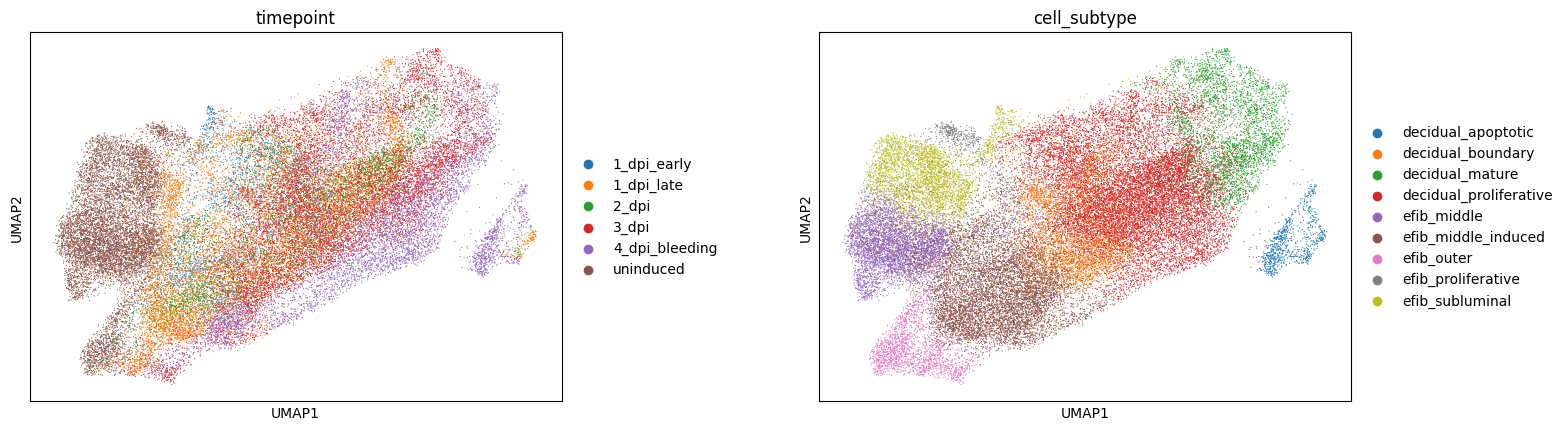

In [14]:
sc.pl.umap(adata, color=["timepoint", CONFIG["cluster_key"]], wspace=0.35, show=False)
savefig("umap_timepoint_subtype")
plt.show()

## moscot: TemporalProblem

In [15]:
from moscot.problems.time import TemporalProblem

tp = TemporalProblem(adata)
tp = tp.score_genes_for_marginals(
    gene_set_proliferation=CONFIG["moscot_gene_set"],   # species-specific marker set
    gene_set_apoptosis=CONFIG["moscot_gene_set"],
)
tp = tp.prepare(time_key="day", joint_attr="X_scVI")
tp = tp.solve(
    epsilon=CONFIG["moscot_epsilon"],
    tau_a=CONFIG["moscot_tau_a"],
    tau_b=CONFIG["moscot_tau_b"],
    scale_cost="mean",
)

computing score 'proliferation'
    finished (0:00:01)
computing score 'apoptosis'
    finished (0:00:01)
INFO     Solving `5` problems                                                                                      
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(9334, 2688)].                                  
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10673, 6141)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(2688, 10787)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(3574, 10673)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10787, 3574)].                                 


## RealTimeKernel → transition matrix

In [16]:
# cellrank's transition_matrix setter rejects any matrix whose rows don't sum to 1
# (rtol=1e-12), and the stitched moscot couplings routinely leave a few all-zero
# rows — cells that no coupling reached. This is the workaround from
# realtime_informed_pseudotime_human.ipynb cells 28-30, which is LOAD-BEARING, not
# diagnostic: catch the matrix before the setter, repair dead rows with a
# within-timepoint uniform, renormalize exactly, then assign.
#
# Mouse (5 transitions) hit this with 6 dead rows. Human (1 transition) did not.

rtk = cr.kernels.RealTimeKernel.from_moscot(tp)

try:
    rtk = rtk.compute_transition_matrix(
        self_transitions=CONFIG["rtk_self_transitions"],
        conn_weight=CONFIG["rtk_conn_weight"],
        threshold=CONFIG["rtk_threshold"],
    )
    T = rtk.transition_matrix
    print("RealTimeKernel accepted the stitched matrix directly")

except ValueError as e:
    if "row stochastic" not in str(e):
        raise
    print(f"RealTimeKernel rejected the matrix: {e}")
    print("applying the documented repair ...")

    if getattr(rtk, "_transition_matrix", None) is not None:
        T = rtk._transition_matrix
    else:
        tmap = rtk._restich_couplings(
            rtk.couplings,
            self_transitions=CONFIG["rtk_self_transitions"],
            conn_weight=CONFIG["rtk_conn_weight"],
        )
        T = tmap.X

    T = csr_matrix(T).tocsr()
    rs = np.asarray(T.sum(axis=1)).ravel()
    dead = np.where(~np.isfinite(rs) | (rs == 0))[0]
    print(f"  dead rows (zero / non-finite): {len(dead)}")

    day_vals = adata.obs["day"].astype(float).to_numpy()
    if len(dead):
        T_lil = T.tolil()
        for i in dead:
            same_tp = np.where(day_vals == day_vals[i])[0]
            T_lil.rows[i] = list(same_tp)
            T_lil.data[i] = [1.0 / len(same_tp)] * len(same_tp)
        T = T_lil.tocsr()

    rs = np.asarray(T.sum(axis=1)).ravel()
    T = csr_matrix(T.multiply(1.0 / rs[:, None]))
    rs2 = np.asarray(T.sum(axis=1)).ravel()
    print(f"  after repair: row sums [{rs2.min():.15f}, {rs2.max():.15f}]")
    print(f"  non-stochastic (rtol=1e-12): {int((~np.isclose(rs2, 1.0, rtol=1e-12)).sum())}")

    rtk.transition_matrix = T
    T = rtk.transition_matrix
    print("  assigned successfully")

rs = np.asarray(T.sum(axis=1)).ravel()
print(f"\ntransition matrix {T.shape}  row sums [{rs.min():.9f}, {rs.max():.9f}]")
assert np.allclose(rs, 1.0, atol=1e-6)


  0%|          | 0/5 [00:00<?, ?time pair/s]

Using automatic `threshold=3.0828566215145976e-44`
RealTimeKernel rejected the matrix: Transition matrix is not row stochastic, 4 rows do not sum to 1.
applying the documented repair ...
  dead rows (zero / non-finite): 4
  after repair: row sums [0.999999999999999, 1.000000000000000]
  non-stochastic (rtol=1e-12): 0
  assigned successfully

transition matrix (43197, 43197)  row sums [1.000000000, 1.000000000]


## DPT eigen-decomposition on the symmetrized matrix

In [17]:
dpt = DPT(adata=adata, neighbors_key="neighbors")
dpt._transitions_sym = get_symmetric_transition_matrix(rtk.transition_matrix)
dpt.compute_eigen(n_comps=CONFIG["n_diffmap_comps"], random_state=CONFIG["seed"])

adata.obsm["X_diffmap"] = dpt.eigen_basis
adata.uns["diffmap_evals"] = dpt.eigen_values

print("Top eigenvalues:", adata.uns["diffmap_evals"][:10])
print(f"X_diffmap shape: {adata.obsm['X_diffmap'].shape}")

    eigenvalues of transition matrix
    [0.99988496 0.9880459  0.9801508  0.97713244 0.9727044  0.9639246
     0.96232325 0.9613787  0.9563863  0.955819   0.9466834  0.9453463
     0.93835217 0.93495995 0.9330153 ]
Top eigenvalues: [0.99988496 0.9880459  0.9801508  0.97713244 0.9727044  0.9639246
 0.96232325 0.9613787  0.9563863  0.955819  ]
X_diffmap shape: (43197, 15)


## Root cell selection

Mouse anchors on `efib_proliferative`; within that pool the root is the cell farthest
(in DC2/DC3) from the centroid of everything else — i.e. the extreme of the trajectory.

Human has no fine stromal label, so the pool becomes the earliest-timepoint cells. Same
geometric rule, weaker biological anchor.

In [18]:
dc23 = adata.obsm["X_diffmap"][:, [2, 3]]
cluster_key = CONFIG["cluster_key"]
anchor = CONFIG["root_candidate_label"]

labels = adata.obs[cluster_key].astype(str)
if anchor in set(labels.unique()):
    root_mask = (labels == anchor).values
    root_source = f"{cluster_key}={anchor}"
else:
    earliest_day = adata.obs["day"].astype(float).min()
    root_mask = (adata.obs["day"].astype(float) == earliest_day).values
    root_source = f"earliest day ({earliest_day}) — {anchor!r} absent after filtering"
    print(f"WARNING: {anchor!r} not found; using earliest-timepoint cells")

print(f"Root source: {root_source}")
print(f"Candidate pool: {int(root_mask.sum()):,} cells")
assert root_mask.sum() > 0, "empty root candidate pool"

target_centroid = dc23[~root_mask].mean(axis=0)
candidate_indices = np.where(root_mask)[0]
dists = np.linalg.norm(dc23[root_mask] - target_centroid, axis=1)

direction = CONFIG["root_direction"]
assert direction in ("far", "near"), direction
pick = dists.argmax() if direction == "far" else dists.argmin()
root_idx = int(candidate_indices[pick])
print(f"root_direction = {direction!r}  "
      f"(dist to non-candidate centroid: {dists[pick]:.4f}, "
      f"pool range [{dists.min():.4f}, {dists.max():.4f}])")

print(f"\nRoot cell: obs index {root_idx}")
print(f"  obs_name  = {adata.obs_names[root_idx]}")
print(f"  timepoint = {adata.obs['timepoint'].iloc[root_idx]}")
print(f"  day       = {adata.obs['day'].iloc[root_idx]}")
print(f"  subtype   = {adata.obs[cluster_key].iloc[root_idx]}")
print(f"  DC2, DC3  = {dc23[root_idx]}")

adata.obs["is_root"] = "other"
adata.obs.loc[adata.obs.index[root_idx], "is_root"] = "root"
adata.obs["is_root"] = adata.obs["is_root"].astype("category")

Root source: cell_subtype=efib_proliferative
Candidate pool: 780 cells
root_direction = 'near'  (dist to non-candidate centroid: 0.0001, pool range [0.0001, 0.0037])

Root cell: obs index 4812
  obs_name  = GAGGGTACACATTGTG-1-uninduced_mck8a
  timepoint = uninduced
  day       = 0.0
  subtype   = efib_proliferative
  DC2, DC3  = [-7.9012525e-06  1.0854623e-04]


In [29]:
direction = CONFIG["root_direction"]
assert direction in ("far", "near"), direction

# global DC2 extreme, no cluster/day restriction
pick = dc23[:, 0].argmax() if direction == "far" else dc23[:, 0].argmin()
root_idx = int(pick)

print(f"root_direction = {direction!r}  "
      f"(DC2 = {dc23[root_idx, 0]:.4f}, "
      f"range [{dc23[:,0].min():.4f}, {dc23[:,0].max():.4f}])")
print(f"\nRoot cell: obs index {root_idx}")
print(f"  obs_name  = {adata.obs_names[root_idx]}")
print(f"  subtype   = {adata.obs[cluster_key].iloc[root_idx]}")
print(f"  DC2, DC3  = {dc23[root_idx]}")

root_direction = 'near'  (DC2 = -0.0314, range [-0.0314, 0.0144])

Root cell: obs index 7814
  obs_name  = AGGTAGGAGGAAAGTG-1-uninduced_mck8b
  subtype   = efib_outer
  DC2, DC3  = [-0.031439222   0.0055604307]


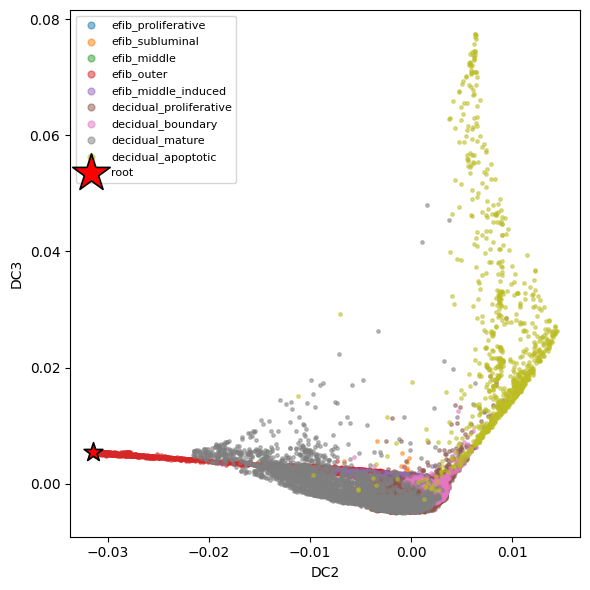

In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

# all cells, colored by cluster
for lab in labels.unique():
    m = (labels == lab).values
    ax.scatter(dc23[m, 0], dc23[m, 1], s=6, alpha=0.5, label=lab)

# root on top
ax.scatter(dc23[root_idx, 0], dc23[root_idx, 1],
           s=200, c="red", marker="*", edgecolor="black",
           linewidth=1.2, zorder=5, label="root")

ax.set_xlabel("DC2")
ax.set_ylabel("DC3")
ax.legend(markerscale=2, fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## Compute DPT pseudotime

In [31]:
adata.uns["iroot"] = root_idx
sc.tl.dpt(adata)

pt = adata.obs["dpt_pseudotime"]
print(f"dpt_pseudotime range: [{pt.min():.4f}, {pt.max():.4f}]")
print(f"non-finite values: {int((~np.isfinite(pt)).sum())}")

computing Diffusion Pseudotime using n_dcs=10
    finished (0:00:00)
dpt_pseudotime range: [0.0000, 1.0000]
non-finite values: 0


## Diagnostics

The Spearman ρ between day and pseudotime is the headline number: it says whether the
trajectory recovered the real-time ordering. Expect it to be **much stronger for mouse**
(5 transitions) than human (1).

  saved pseudotime_mouse/figures/v1_all_cells/umap_pseudotime_day.pdf


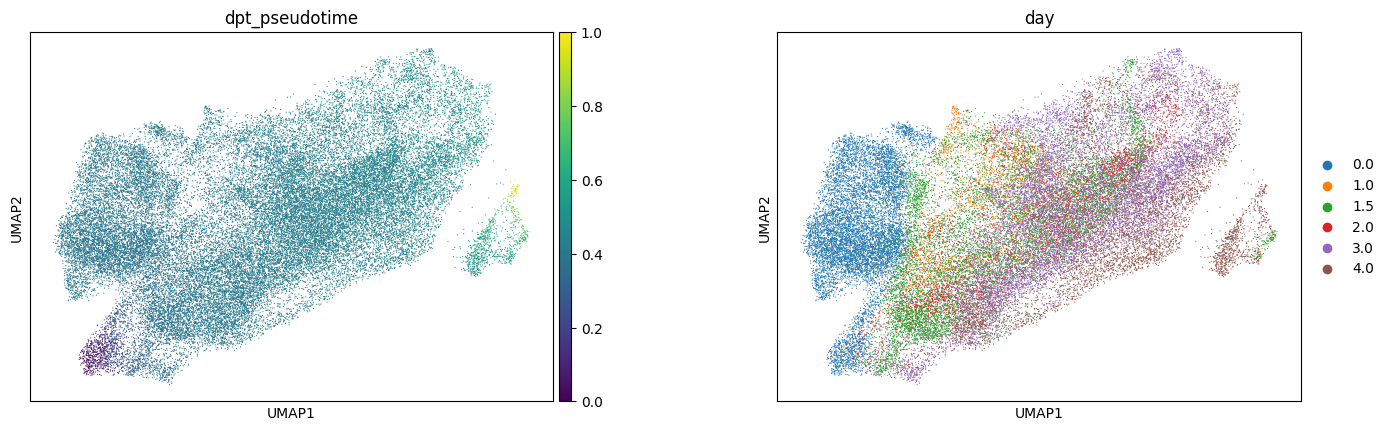

  saved pseudotime_mouse/figures/v1_all_cells/diffmap_pseudotime_day.pdf


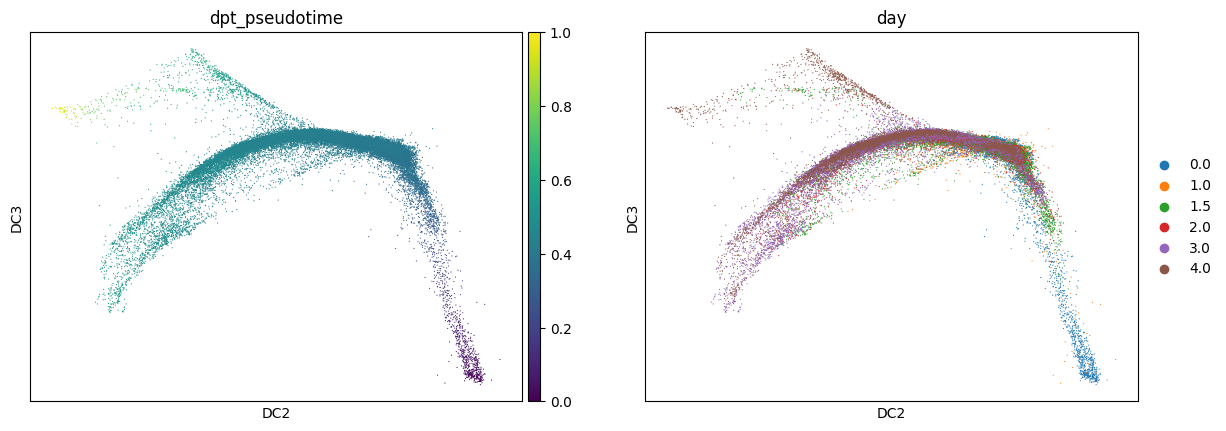

In [32]:
sc.pl.umap(adata, color=["dpt_pseudotime", "day"], wspace=0.3, cmap="viridis", show=False)
savefig("umap_pseudotime_day")
plt.show()

sc.pl.diffmap(adata, color=["dpt_pseudotime", "day"], components="2,3",
              cmap="viridis", show=False)
savefig("diffmap_pseudotime_day")
plt.show()

2026-08-28 23:10:57 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-28 23:10:57 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-28 23:10:57 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


  saved pseudotime_mouse/figures/v1_all_cells/violin_pseudotime_by_day.pdf


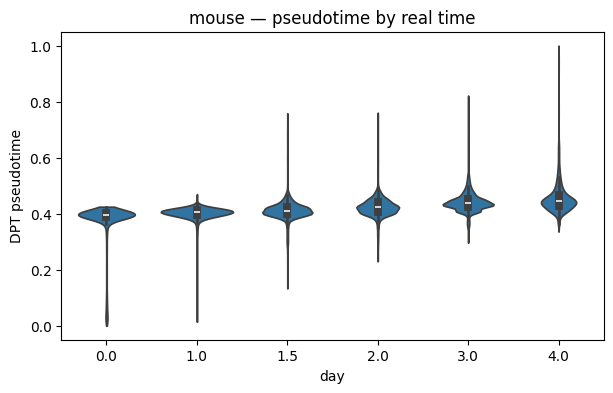

In [33]:
fig, ax = plt.subplots(figsize=(7, 4))
order = [str(c) for c in sorted(adata.obs["day"].astype(float).unique())]
plot_df = pd.DataFrame({
    "day": adata.obs["day"].astype(float).astype(str).values,
    "dpt_pseudotime": adata.obs["dpt_pseudotime"].values,
})
sns.violinplot(data=plot_df, x="day", y="dpt_pseudotime", order=order, ax=ax, cut=0)
ax.set_xlabel("day")
ax.set_ylabel("DPT pseudotime")
ax.set_title(f"{SPECIES} — pseudotime by real time")
savefig("violin_pseudotime_by_day")
plt.show()

In [35]:
day_num = adata.obs["day"].astype(float).values
ptv = adata.obs["dpt_pseudotime"].values
ok = np.isfinite(ptv) & np.isfinite(day_num)

rho, pval = spearmanr(day_num[ok], ptv[ok])
print(f"Spearman rho (day vs pseudotime): {rho:.4f}   p = {pval:.3e}   n = {ok.sum():,}")

print(f"\nmean pseudotime per {CONFIG['cluster_key']}:")
print(adata.obs.groupby(CONFIG["cluster_key"], observed=True)["dpt_pseudotime"]
      .agg(["mean", "median", "count"]).sort_values("mean").to_string())

print("\nmean pseudotime per day:")
print(adata.obs.groupby("day", observed=True)["dpt_pseudotime"]
      .agg(["mean", "median", "count"]).to_string())

Spearman rho (day vs pseudotime): 0.6654   p = 0.000e+00   n = 43,197

mean pseudotime per cell_subtype:
                            mean    median  count
cell_subtype                                     
efib_outer              0.246340  0.302877   2073
efib_middle             0.392661  0.392601   4764
efib_middle_induced     0.397965  0.399934   8775
efib_proliferative      0.404027  0.405053    780
efib_subluminal         0.405648  0.406136   3886
decidual_boundary       0.420672  0.421327   3722
decidual_proliferative  0.435558  0.434809  14434
decidual_mature         0.477975  0.473647   3856
decidual_apoptotic      0.595008  0.565375    907

mean pseudotime per day:
         mean    median  count
day                           
0.0  0.369778  0.394933   9334
1.0  0.397886  0.404835   2688
1.5  0.412113  0.410518  10787
2.0  0.423776  0.422242   3574
3.0  0.439813  0.436545  10673
4.0  0.460035  0.444021   6141


### Orientation gate

Pseudotime should increase with real time. A negative ρ means the root sits at the wrong
end — flip it by choosing the opposite extreme in the root cell rather than negating the
pseudotime.

In [36]:
ORIENTATION_OK = rho > 0
print(f"orientation: {'OK' if ORIENTATION_OK else 'INVERTED'}   (rho = {rho:.4f})")
if not ORIENTATION_OK:
    print(
        "\n  -> Root is at the late end. Re-select it as the candidate cell CLOSEST to\n"
        "     the target centroid (dists.argmin() instead of argmax) and recompute.\n"
        "     Do NOT just negate dpt_pseudotime — downstream code assumes [0, 1]."
    )

orientation: OK   (rho = 0.6654)


## Statistics (matching `dac_fig.ipynb`)

Four Spearman variants plus per-group medians — the same set the project's figure
notebook reports, with `SUBTYPE_ORDER` translated to the v2 vocabulary.

**Reference values from the headless runs (2026-08-28):**

| statistic | mouse (`root_direction="far"`) | human |
|---|---|---|
| all cells vs day | **−0.4933** (inverted) | +0.0767 |
| subtype rank | **−0.7693** (inverted) | n/a — no fine subtypes |
| decidual only | −0.2819 | n/a |
| fibroblasts only | +0.0307 | n/a |

With `root_direction="near"` the mouse signs should flip. |ρ| ≈ 0.77 on subtype rank
means the trajectory is strong; only its direction was wrong.


In [37]:
FIB_SUBTYPES = ["efib_outer", "efib_middle", "efib_middle_induced",
                "efib_subluminal", "efib_proliferative"]
DEC_SUBTYPES = ["decidual_boundary", "decidual_proliferative",
                "decidual_mature", "decidual_apoptotic"]
SUBTYPE_ORDER = FIB_SUBTYPES + DEC_SUBTYPES

ptv = adata.obs["dpt_pseudotime"].to_numpy()
dayv = adata.obs["day"].astype(float).to_numpy()
subv = adata.obs[CONFIG["cluster_key"]].astype(str).to_numpy()


def stats_block(pt, day, label):
    ok = np.isfinite(pt) & np.isfinite(day)
    if ok.sum() < 10:
        print(f"\n[{label}] skipped (n={int(ok.sum())})")
        return None
    rho, p = spearmanr(pt[ok], day[ok])
    print(f"\n[{label}]  n={int(ok.sum()):,}   Spearman(pt, day) rho={rho:+.4f}  p={p:.3e}")
    tbl = (pd.DataFrame({"day": day[ok], "pt": pt[ok]})
           .groupby("day")["pt"].agg(["median", "mean", "std", "count"]))
    print(tbl.to_string())
    return rho


rho_all = stats_block(ptv, dayv, "all cells")

fib_m = np.isin(subv, FIB_SUBTYPES)
dec_m = np.isin(subv, DEC_SUBTYPES)
print(f"\nfibroblast cells: {int(fib_m.sum()):,}   decidual cells: {int(dec_m.sum()):,}")

rho_fib = stats_block(ptv[fib_m], dayv[fib_m], "fibroblasts only") if fib_m.sum() >= 10 else None
rho_dec = stats_block(ptv[dec_m], dayv[dec_m], "decidual only") if dec_m.sum() >= 10 else None

# Spearman(pt, subtype rank) — the ordering test
rank_map = {s: i for i, s in enumerate(SUBTYPE_ORDER)}
ranks = np.array([rank_map.get(s, np.nan) for s in subv], dtype=float)
ok = np.isfinite(ranks) & np.isfinite(ptv)

if ok.sum() >= 10:
    rho_rank, p_rank = spearmanr(ptv[ok], ranks[ok])
    print(f"\n[subtype rank]  n={int(ok.sum()):,}   "
          f"Spearman(pt, subtype_rank) rho={rho_rank:+.4f}  p={p_rank:.3e}")
    by_sub = (pd.DataFrame({
                  "subtype": pd.Categorical(subv[ok], categories=SUBTYPE_ORDER, ordered=True),
                  "pt": ptv[ok]})
              .groupby("subtype", observed=True)["pt"]
              .agg(["median", "mean", "std", "count"]))
    print("\nmedian pt by subtype (ordered fibroblast -> decidual):")
    print(by_sub.to_string())
    print("\nIf median pt DECREASES down this table, the root is at the wrong end:")
    print('  set CONFIG["root_direction"] to the other value and re-run.')
else:
    rho_rank = None
    print("\n[subtype rank] skipped — no fine subtypes "
          "(expected for human: cell_subtype is coarse-filled)")



[all cells]  n=43,197   Spearman(pt, day) rho=+0.6654  p=0.000e+00
       median      mean       std  count
day                                     
0.0  0.394933  0.369778  0.087268   9334
1.0  0.404835  0.397886  0.039131   2688
1.5  0.410518  0.412113  0.038202  10787
2.0  0.422242  0.423776  0.038273   3574
3.0  0.436545  0.439813  0.031696  10673
4.0  0.444021  0.460035  0.069591   6141

fibroblast cells: 20,278   decidual cells: 22,919

[fibroblasts only]  n=20,278   Spearman(pt, day) rho=+0.2538  p=1.845e-295
       median      mean       std  count
day                                     
0.0  0.394857  0.369570  0.087529   9270
1.0  0.396516  0.386392  0.049907   1425
1.5  0.396801  0.389911  0.027311   5133
2.0  0.398979  0.392188  0.025297   1170
3.0  0.407323  0.402513  0.021899   1998
4.0  0.410136  0.408666  0.016264   1282

[decidual only]  n=22,919   Spearman(pt, day) rho=+0.5335  p=0.000e+00
       median      mean       std  count
day                                 

## Spatial visualization

Coordinates are per-sample/per-timepoint frames — **never pool them into one scatter.**
Human samples in particular live on separate coordinate systems per timepoint.

In [ ]:
sample_col = CONFIG["spatial_sample_col"]
x_col, y_col = CONFIG["spatial_x_col"], CONFIG["spatial_y_col"]

has_xy = adata.obs[[x_col, y_col]].notna().all(axis=1).values
print(f"cells with coordinates: {has_xy.sum():,} / {adata.n_obs:,} ({100*has_xy.mean():.1f}%)")

samples = [s for s in adata.obs[sample_col].astype(str).unique()
           if has_xy[(adata.obs[sample_col].astype(str) == s).values].sum() > 0]
print(f"samples with coordinates: {len(samples)}")

ncol = 4
nrow = int(np.ceil(len(samples) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4 * nrow), squeeze=False)

for ax, s in zip(axes.ravel(), samples):
    m = (adata.obs[sample_col].astype(str) == s).values & has_xy
    sub = adata.obs.loc[m]
    sc_ = ax.scatter(sub[x_col], sub[y_col], c=sub["dpt_pseudotime"],
                     cmap="viridis", s=4, vmin=0, vmax=1)
    tp_label = sub["timepoint"].iloc[0] if len(sub) else "?"
    ax.set_title(f"{s}\n{tp_label}  (n={m.sum():,})", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])

for ax in axes.ravel()[len(samples):]:
    ax.axis("off")

fig.colorbar(sc_, ax=axes, shrink=0.5, label="DPT pseudotime")
savefig("spatial_pseudotime_by_sample")
plt.show()

## Save outputs

In [38]:
adata.obs["dpt_pseudotime_integrated"] = adata.obs["dpt_pseudotime"].copy()

out_h5ad = RESULTS_DIR / f"{DATE_TAG}_{SPECIES}_fibdec_pseudotime.h5ad"
tmp = out_h5ad.with_suffix(".h5ad.tmp")
adata.write_h5ad(tmp)
os.replace(tmp, out_h5ad)
print(f"wrote {out_h5ad}")

obs_cols = ["sample", "timepoint", "day", "cell_type", CONFIG["cluster_key"],
            "dpt_pseudotime", x_col, y_col]
obs_cols = [c for c in obs_cols if c in adata.obs.columns]
adata.obs[obs_cols].to_csv(RESULTS_DIR / f"{SPECIES}_pseudotime_obs.csv")

summary = {
    "species": SPECIES,
    "variant": VARIANT,
    "input": str(ADATA_PATH),
    "n_cells": int(adata.n_obs),
    "n_timepoints": int(len(adata.obs["day"].cat.categories)),
    "n_transitions": int(len(adata.obs["day"].cat.categories) - 1),
    "root_source": root_source,
    "root_obs_name": str(adata.obs_names[root_idx]),
    "root_timepoint": str(adata.obs["timepoint"].iloc[root_idx]),
    "root_subtype": str(adata.obs[cluster_key].iloc[root_idx]),
    "anchor_available": bool(ANCHOR_AVAILABLE),
    "spearman_rho_day_vs_pseudotime": float(rho),
    "spearman_p": float(pval),
    "orientation_ok": bool(ORIENTATION_OK),
    "scvi_source": CONFIG["scvi_source"],
    "root_direction": CONFIG["root_direction"],
    "cells_with_coords": int(has_xy.sum()),
    "config": {k: (str(v) if not isinstance(v, (int, float, bool, str, type(None), list, dict)) else v)
               for k, v in CONFIG.items()},
}
(RESULTS_DIR / f"{SPECIES}_pseudotime_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps({k: v for k, v in summary.items() if k != "config"}, indent=2))

wrote pseudotime_mouse/results/v1_all_cells/2026_08_28_mouse_fibdec_pseudotime.h5ad


NameError: name 'x_col' is not defined

---

## Running this

Needs a **GPU node** — moscot requires JAX on GPU and scVI wants CUDA:

```bash
salloc -p gpu --gres=gpu:1 -t 0-04:00 --mem=64G
```

Then Jupyter via Open OnDemand with the same resources, kernel `Python (rsc_uv)`.

Keep caches off HOME (it runs ~90-95% full):

```bash
export XDG_CACHE_HOME=/n/lab_storage/eddy_lab/users/nhilgert/.cache_scratch
export NUMBA_CACHE_DIR=$XDG_CACHE_HOME/numba
export MPLCONFIGDIR=$XDG_CACHE_HOME/mpl
export TMPDIR=/n/lab_storage/eddy_lab/users/nhilgert/tmp
```

### Suggested runs

| variant | `remove_apoptotic` | `remove_fibroblasts` | why |
|---|---|---|---|
| `v1_all_cells` | False | False | baseline |
| `v2_no_apoptotic` | True | False | `decidual_apoptotic` is a terminal state and can pull the trajectory |
| `v3_prolif_only` | False | True | keeps only `efib_proliferative` among fibroblasts |

Mouse only: set `remove_uninduced=True` to drop the pre-induction timepoint.
Variants 2 and 3 are mouse-only in effect — the human object has no fine labels to filter on.

### What to check first

1. **Spearman ρ** — mouse should be clearly positive. A weak or negative value on mouse
   means the root is wrong, not the method.
2. **The orientation gate** — if inverted, re-pick the root at the other extreme rather
   than negating pseudotime.
3. **Root identity** — `root_source` in the summary JSON records whether the anchor was
   used or the fallback was taken.